# Banka Kampanyalarında Keşifsel Veri Analizi

**Proje:** bank-marketing-eda · **Düzey:** İstatistik lisans · **Kapsam:** EDA, model yok.

Amaç eksik bilgiyi, finansal dağılımları ve kampanya kayıtlarının örüntülerini
gerçek veriyle incelemektir. Her grafik bir soru, ölçülmüş bulgu ve sınırlama içerir.

## Üç araştırma sorusu
1. Eksik müşteri/temas bilgisi nerede ve hangi birlikte eksiklik örüntülerinde yoğunlaşıyor?
2. Bakiye dağılımında çarpıklık ve IQR ile işaretlenen gözlemler nasıl yorumlanmalı?
3. Eğitim ve temas sayısı gruplarında gözlenen abonelik oranları nasıl farklılaşıyor?

## Kaynak ve lisans
[UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing),
**bank-full.csv** eski sürümü (balance alanı EUR). CC BY 4.0; atıf zorunludur.
bank-additional-full.csv ile karıştırılmamalıdır. Atıflar `docs/sources_and_license.md` içindedir.

UCI 'eksik yok' der; dosyada boş/NA yerine bazı alanlarda `unknown` vardır.
Bu anlamsal bilinmeyenleri (semantic missingness) inceliyoruz; yapay eksik üretmiyoruz.
`pdays=-1` ise önceki temasın olmaması anlamındadır: yapısal uygulanamazlık (not applicable).


In [1]:
from pathlib import Path
import sys
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis.py').exists(), 'Çalışma dizini proje klasörü olmalı.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.download import ensure_raw, digest
from src.analysis import load_raw, audit_raw, clean_data, build_tables, plot_all, export_results
pd.set_option('display.max_columns', 24)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')


## 1. Ham veri ve kaynak kaydı
Ham dosyaya yazmıyoruz. İlk çalıştırma UCI arşivini indirir; sonraki çalıştırma
aynı anlık görüntünün hash'ini doğrular. Veri güncellenirse eski bulguların aynı
kalacağı varsayılmaz. Kaynağın boş değer kodlarını otomatik dönüştürmemek için
CSV önce metin olarak okunur; sayısal dönüşüm kontrollü yapılır.

In [2]:
raw_path, metadata = ensure_raw()
raw_hash_before = digest(raw_path.read_bytes())
raw = load_raw(raw_path)
display(pd.Series({
    'kaynak': metadata['source_page'], 'sürüm': metadata['variant'],
    'indirme_UTC': metadata['retrieved_at_utc'], 'lisans': metadata['license'],
    'ham_satır': len(raw), 'ham_sütun': raw.shape[1], 'sha256': raw_hash_before
}).to_frame('değer'))
display(raw.head())

,değer
kaynak,https://archive.ics.uci.edu/dataset/222/bank+m...
sürüm,bank-full.csv (older version)
indirme_UTC,2026-10-20T07:49:37.565295+00:00
lisans,CC BY 4.0
ham_satır,45211
ham_sütun,17
sha256,d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa...


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Veri tipleri, alan kuralları ve tekrarlar
Yaş yıl, bakiye EUR, görüşme süresi saniye; campaign/previous temas sayısıdır.
CSV önce metin yüklendiği için başlangıçtaki metin tipleri kaynağın gerçek
ölçüm düzeyi değildir. Temizlemede sonlu tamsayılar ve belgelenmiş kategoriler doğrulanır.

Negatif bakiye otomatik hata değildir. Tam yıl/tarih ve müşteri kimliği yoktur;
aynı özelliklere sahip iki satır kesinlikle aynı müşteri sayılmaz. Birebir
tekrarlar sayılır ama kimlik kanıtı olmadan silinmez.

In [3]:
raw_audit = audit_raw(raw)
display(pd.Series({k:v for k,v in raw_audit.items() if not isinstance(v,dict)}).to_frame('değer'))
display(pd.Series(raw_audit['unknown_by_column'], name='unknown_sayısı').to_frame())
clean = clean_data(raw)
display(clean.dtypes.astype(str).to_frame('temiz_veri_tipi'))
display(pd.DataFrame({'aşama':['ham','temiz'], 'satır':[len(raw),len(clean)],
                      'sütun':[raw.shape[1],clean.shape[1]], 'silinen_satır':[0,0]}))

,değer
rows,45211
columns,17
blank_cells,0
literal_null_cells,0
exact_duplicate_rows,0


,unknown_sayısı
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


,temiz_veri_tipi
source_row,int64
age,int64
job,string
marital,string
education,string
default,string
balance,int64
housing,string
loan,string
contact,string


,aşama,satır,sütun,silinen_satır
0,ham,45211,17,0
1,temiz,45211,23,0


## 3. Sütun bazında eksik bilgi kararı
- **job, education, contact:** kaynak `unknown` kodları `pd.NA` olarak tutulur.
  Mod veya ortalamayla doldurulmaz; kategorik grafiklerde bilinmeyen grup gösterilir.
- **pdays:** ham -1 kodu korunur; türetilmiş `pdays_since_prior` alanında bu
  satırlar yapısal boş olarak tutulur. Ortalama alınırken -1 gerçek gün sayılmaz.
- **poutcome:** ham unknown korunur. Türetilmiş önceki sonuçta, temas olmamasına
  bağlı uygulanamazlık ile temas olmasına rağmen bilinmeyen sonuç ayrılır.
- **Diğer alanlar:** beklenmeyen değer veya eksik bulunursa otomatik silinmez;
  doğrulama hata üretir. Mevcut veri üzerinde bulgu neyse o raporlanır.

Tam-vaka silme (complete-case deletion), eksikliği yüksek alanlarda örneklemi
küçültebilir ve bileşimini değiştirebilir. Bu EDA'da satırlar korunur. Eksiklik
mekanizmasının MCAR/MAR/MNAR olduğu kanıtlanmış değildir.

In [4]:
tables = build_tables(raw, clean)
display(tables['missing_profile'])
display(tables['missing_patterns'])
display(clean.prior_outcome_missing_reason.value_counts().to_frame('n'))

,raw_unknown_n,clean_missing_n,missing_pct
job,288,288,0.637
education,1857,1857,4.107
contact,13020,13020,28.798


,n,pct
pattern,,
Eksik yok,30907,68.362
contact,12286,27.175
education,1107,2.449
education + contact,623,1.378
job,104,0.230
job + education,73,0.161
job + contact,57,0.126
job + education + contact,54,0.119


,n
prior_outcome_missing_reason,
not_applicable_no_prior_contact,36954
observed,8252
unknown_despite_prior_contact,5


## 4. Betimsel istatistikler ve aykırı gözlemler
Ortalama uç değerlerden etkilenir; medyan sıralamaya dayanır. Standart sapma
yayılımı, çeyrekler dağılımın orta kısmını özetler. Para, saniye ve sayı
ölçeklerini birbirine karıştırmadan yorumlarız.

**IQR = Q3 − Q1**; alt/üst çitler Q1 − 1,5×IQR ve Q3 + 1,5×IQR.
Çit dışı olmak hata veya dolandırıcılık kanıtı değildir. IQR=0 ise ender fakat
geçerli değerler de işaretlenebilir. Hiçbir aykırı değer silinmez/kırpılmaz.


In [5]:
display(tables['descriptive_statistics'])
display(tables['outlier_profile'])
display(tables['category_counts'])
balance_profile = tables['outlier_profile'].loc['balance']
balance_flags = clean.balance.lt(balance_profile.lower_fence) | clean.balance.gt(balance_profile.upper_fence)
assert int(balance_flags.sum()) == int(balance_profile.flagged_n)
display(clean.loc[balance_flags, ['source_row','balance','age','y']].head(10))

,count,mean,std,min,25%,50%,75%,95%,99%,max,missing_n,unit
age,"45,211.000",40.936,10.619,18.000,33.000,39.000,48.000,59.000,71.000,95.000,0,yıl
balance,"45,211.000","1,362.272","3,044.766","-8,019.000",72.000,448.000,"1,428.000","5,768.000","13,164.900","102,127.000",0,EUR
duration,"45,211.000",258.163,257.528,0.000,103.000,180.000,319.000,751.000,"1,269.000","4,918.000",0,saniye
campaign,"45,211.000",2.764,3.098,1.000,1.000,2.000,3.000,8.000,16.000,63.000,0,temas sayısı
previous,"45,211.000",0.580,2.303,0.000,0.000,0.000,0.000,3.000,8.900,275.000,0,temas sayısı
pdays_since_prior,"8,257.000",224.578,115.344,1.000,133.000,194.000,327.000,370.000,531.440,871.000,36954,gün


,observed_n,q1,q3,iqr,lower_fence,upper_fence,flagged_n,flagged_pct
variable,,,,,,,,
age,45211,33.000,48.000,15.000,10.500,70.500,487,1.077
balance,45211,72.000,"1,428.000","1,356.000","-1,962.000","3,462.000",4729,10.460
duration,45211,103.000,319.000,216.000,-221.000,643.000,3235,7.155
campaign,45211,1.000,3.000,2.000,-2.000,6.000,3064,6.777
previous,45211,0.000,0.000,0.000,0.000,0.000,8257,18.263
pdays_since_prior,8257,133.000,327.000,194.000,-158.000,618.000,49,0.593


,variable,category,n,pct
0,job,blue-collar,9732,21.526
1,job,management,9458,20.920
2,job,technician,7597,16.803
3,job,admin.,5171,11.437
4,job,services,4154,9.188
5,job,retired,2264,5.008
6,job,self-employed,1579,3.493
7,job,entrepreneur,1487,3.289
8,job,unemployed,1303,2.882
9,job,housemaid,1240,2.743


,source_row,balance,age,y
34,35,10635,51,no
65,66,6530,51,no
69,70,12223,35,no
70,71,5935,57,no
186,187,4384,40,no
187,188,4080,54,no
205,206,5699,50,no
334,335,24598,45,no
382,383,8486,40,no
391,392,8730,37,no


## 5. Yedi grafik: soru → bulgu → sınırlama
İşaret koruyan asinh ve symlog, negatif ve yüksek bakiyeleri birlikte görünür
kılar. Bunlar yalnız görüntüleme dönüşümüdür, para değerlerini değiştirmez.
Oranların paydaları gösterilir. Bu çalışma hipotez testi veya nedensel analiz değildir.

In [6]:
figures = plot_all(clean, tables, ROOT / 'reports' / 'figures')
print(f'{len(figures)} grafik üretildi. Ham gözlemlerden hiçbiri çıkarılmadı.')

7 grafik üretildi. Ham gözlemlerden hiçbiri çıkarılmadı.


### Eksik bilgi hangi alanlarda yoğunlaşıyor?

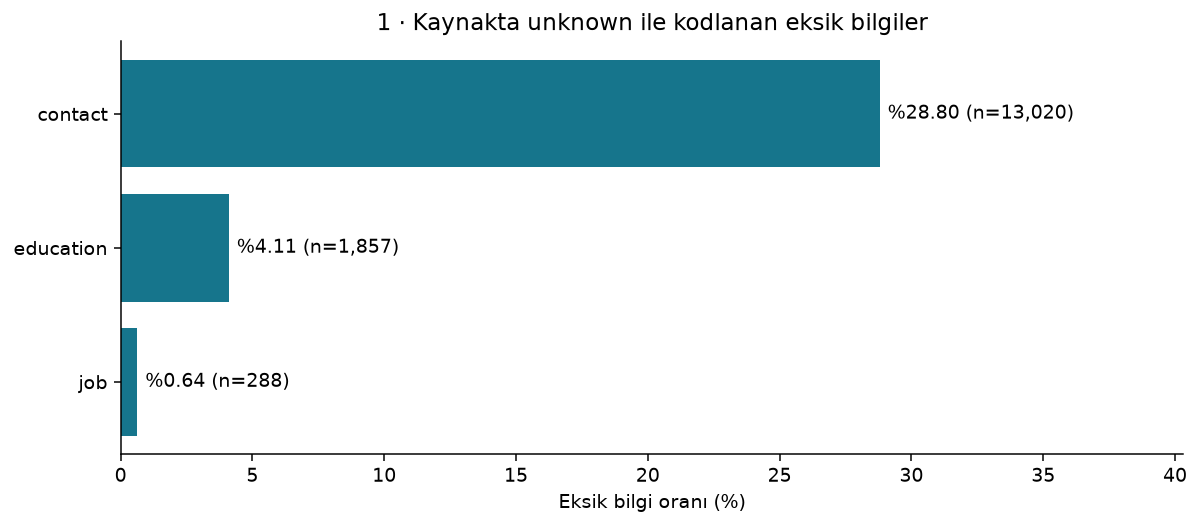

**Bulgu:** En yüksek eksik bilgi oranı contact alanında: %28.80 (n=13,020).

**Sınırlama:** UCI üst verisi boş/NA değer olmadığını bildirir; burada ölçülen, gerçek unknown kodlarının anlamsal eksikliğidir. Eksiklik mekanizması kanıtlanmaz.

In [7]:
note = figures[0]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Eksik bilgiler birlikte mi görülüyor?

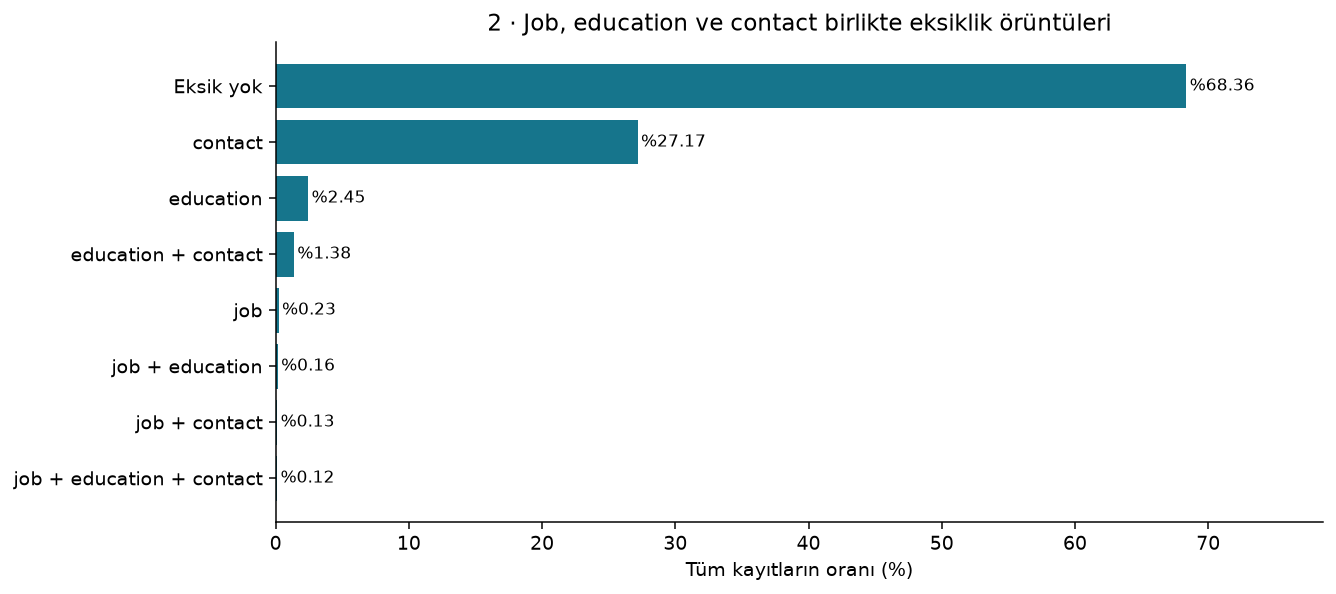

**Bulgu:** Üç alanda da bilgi bulunan 30,907 kayıt var; en az bir eksik alanı olan 14,304 kayıt korunuyor.

**Sınırlama:** Örüntüler yalnız bu üç alanı kapsar; MCAR, MAR veya MNAR sınıflaması için tek başına yeterli değildir.

In [8]:
note = figures[1]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Bakiye dağılımı ve aykırı gözlemler

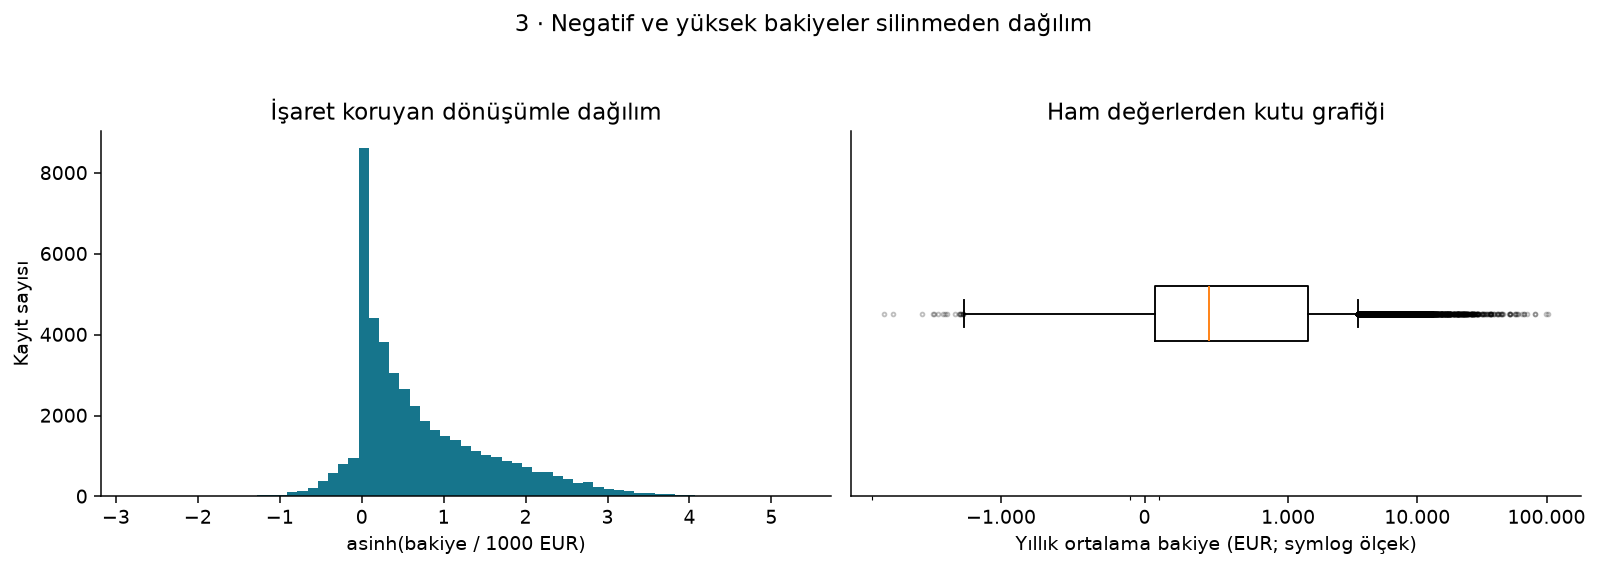

**Bulgu:** Ortalama 1362.27 EUR, medyan 448.00 EUR; negatif bakiyeli 3,766 kayıt var. IQR kuralı 4,729 bakiyeyi işaretliyor (%10.46).

**Sınırlama:** IQR etiketi veri hatası değildir; negatif bakiye de otomatik hata sayılmaz. asinh ve symlog yalnız görselleştirme içindir; temiz bakiye değerleri değiştirilmez.

In [9]:
note = figures[2]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Eğitim gruplarında gözlenen oranlar nasıl?

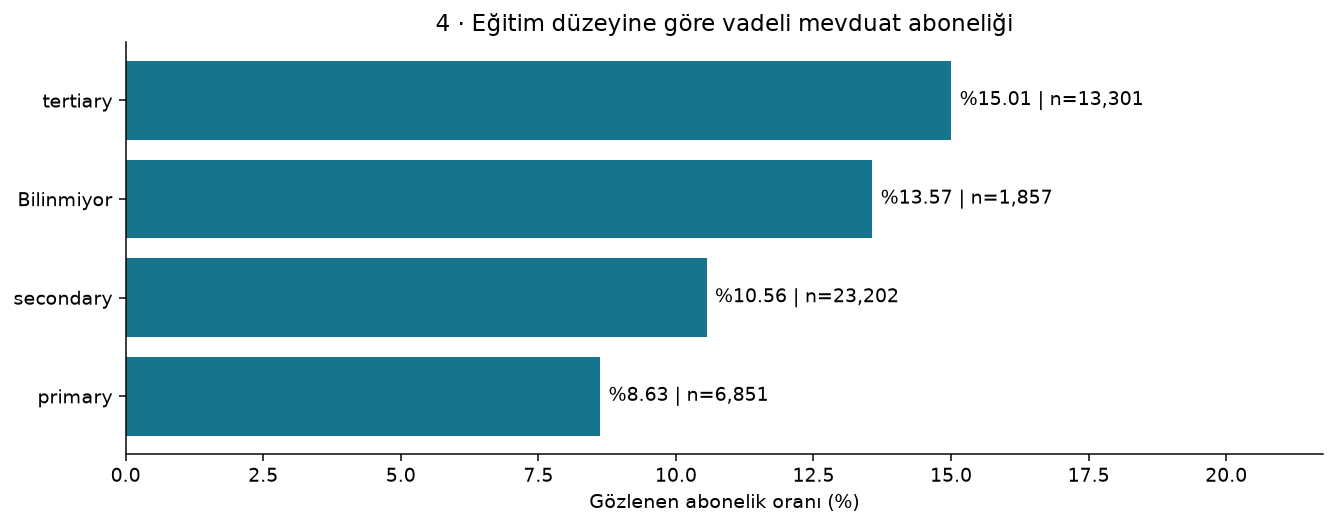

**Bulgu:** En yüksek oran tertiary grubunda %15.01; en düşük primary grubunda %8.63. Paydalar grafikte gösteriliyor; eksik eğitim ayrı grupta tutuldu.

**Sınırlama:** Bunlar örneklem içi betimsel oranlardır; eğitim etkisi veya nedensel fark değildir. Yaş, gelir, seçim ve kampanya bileşimi kontrol edilmedi; güven aralığı veya hipotez testi yapılmadı.

In [10]:
note = figures[3]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Temas sayısı grupları nasıl farklılaşıyor?

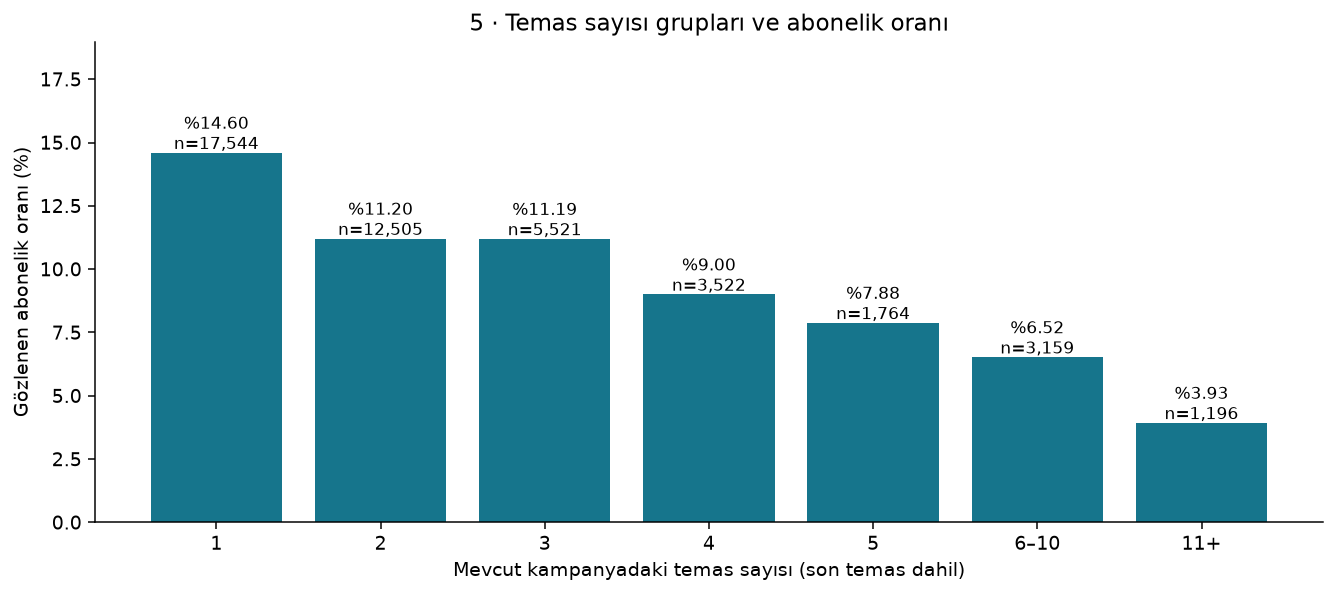

**Bulgu:** Tek temas grubunda oran %14.60 (n=17,544); 11+ temas grubunda %3.93 (n=1,196).

**Sınırlama:** Temas sayısı rastgele atanmadı; zor ikna edilen kayıtlarda daha fazla temas olabilir. Bu sonuçtan arama sayısını azaltmanın aboneliği artıracağı çıkarılamaz.

In [11]:
note = figures[4]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Abone olan ve olmayan kayıtlarda bakiye nasıl?

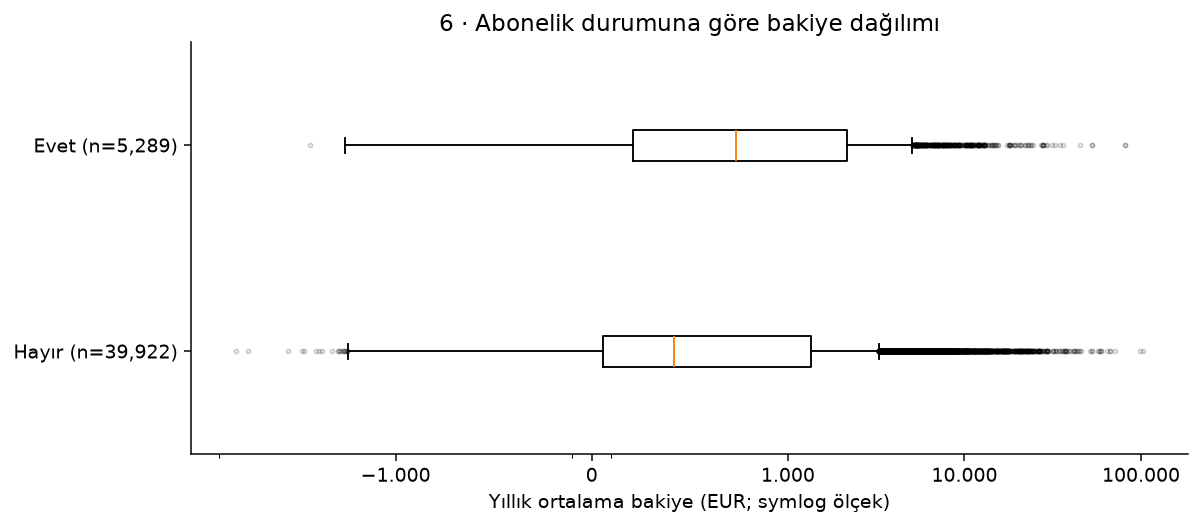

**Bulgu:** Medyan bakiye: abone olmayanlarda 417.00 EUR; olanlarda 733.00 EUR. Her iki grupta da uç değerler korundu.

**Sınırlama:** Gruplar eş büyüklükte değil; bakiye farkı aboneliğe neden olan bir etki veya müşteri geliri ölçümü değildir. Tek bir ortalama/medyan tüm dağılımı anlatmaz.

In [12]:
note = figures[5]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

### Sayısal değişkenler arasında sıralı ilişki var mı?

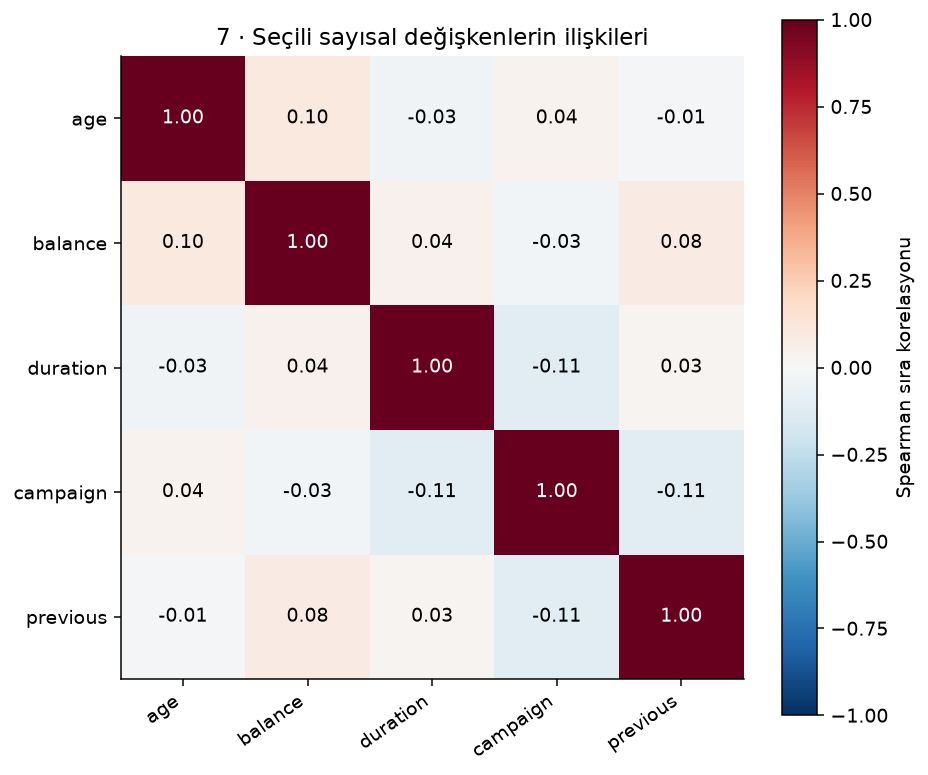

**Bulgu:** Gösterilen çiftlerde mutlak değeri en büyük Spearman katsayısı campaign–previous için -0.108.

**Sınırlama:** Seçili ilişkiler betimseldir; sıfıra yakın katsayı tüm bağımlılıkları dışlamaz. pdays=-1 yapısal kodu korelasyona alınmadı. duration görüşme sonrası bilinir; önceden hedefleme özelliği gibi kullanılamaz.

In [13]:
note = figures[6]
display(Markdown('### ' + note['title']))
display(Image(filename=str(ROOT / 'reports' / 'figures' / note['filename'])))
display(Markdown('**Bulgu:** ' + note['finding'] + '\n\n**Sınırlama:** ' + note['limitation']))

## 6. Araştırma sorularının sayısal özeti
Abonelik (`y`) yalnız betimsel grup karşılaştırmasında kullanıldı; tahmin modeli
eğitilmedi. `duration` son görüşme bitince bilinir; ileride bir hedefleme modeli
kurulursa önceden bilinebilen değişkenmiş gibi kullanılması sızıntı riski taşır.

In [14]:
display(tables['education_rates'])
display(tables['campaign_rates'])
display(tables['spearman'])
display(Markdown(f'Genel gözlenen abonelik oranı: **%{100*clean.subscribed.mean():.2f}**. '
                 'Bu oran yalnız mevcut kampanya kayıtlarını betimler.'))

,n,yes_n,rate,rate_pct
group,,,,
Bilinmiyor,1857,252,0.136,13.570
primary,6851,591,0.086,8.626
secondary,23202,2450,0.106,10.559
tertiary,13301,1996,0.150,15.006


,n,yes_n,rate,rate_pct
group,,,,
1,17544,2561,0.146,14.598
2,12505,1401,0.112,11.204
3,5521,618,0.112,11.194
4,3522,317,0.090,9.001
5,1764,139,0.079,7.880
6–10,3159,206,0.065,6.521
11+,1196,47,0.039,3.930


,age,balance,duration,campaign,previous
age,1.000,0.096,-0.033,0.037,-0.012
balance,0.096,1.000,0.043,-0.031,0.080
duration,-0.033,0.043,1.000,-0.108,0.031
campaign,0.037,-0.031,-0.108,1.000,-0.108
previous,-0.012,0.080,0.031,-0.108,1.000


Genel gözlenen abonelik oranı: **%11.70**. Bu oran yalnız mevcut kampanya kayıtlarını betimler.

## 7. Bütünlük kontrolleri ve dosyaların dışa aktarımı
Gözlem sayısı, bakiye, sonuç etiketi, kaynak sıra kimliği, eksiklik dönüşümü,
grup paydaları ve ham dosyanın hash'i kontrol edilir. Temiz veri ayrı dosyadır.
Testler model başarısını değil veri işlemlerinin doğruluğunu sınar.

In [15]:
audit = export_results(raw, clean, tables, figures, metadata)
assert digest(raw_path.read_bytes()) == raw_hash_before
display(pd.Series(audit['checks']).to_frame('geçti'))
environment = {'python':platform.python_version(), 'packages':{
    name:version(name) for name in ['pandas','numpy','matplotlib','nbformat','nbclient','ipykernel']}}
(ROOT / 'reports' / 'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
print('Temiz veri, tablo CSV dosyaları, grafikler ve bulgu raporu kaydedildi.')

,geçti
same_row_count,True
balance_unchanged,True
original_outcome_unchanged,True
missing_codes_exactly_mapped,True
all_source_rows_unique_and_retained,True
pdays_sentinel_preserved,True
structural_days_missing_correctly,True
missing_pattern_counts_sum_to_rows,True
education_group_counts_sum_to_rows,True
campaign_group_counts_sum_to_rows,True


Temiz veri, tablo CSV dosyaları, grafikler ve bulgu raporu kaydedildi.


## 8. Sonuçların sınırı ve öğrenme
- Tek bankanın tarihsel kampanya örneklemi güncel Türkiye müşteri kitlesi değildir.
- Örneklem seçimi, eksik bilgi ve müşteri kimliğinin olmaması yorumu sınırlar.
- Grup farkı ve korelasyon nedensellik değildir; güven aralığı veya p değeri üretmedik.
- Eksik bilgileri korumak bir analiz kararıdır; gelecekteki model için her durumda
  doğru doldurma yöntemi olduğunu iddia etmiyoruz.

**Kendine sor:** Negatif bakiye neden silinmedi? IQR=0 ne demek?
`pdays=-1` ile `education=unknown` neden aynı tür eksiklik değil?
Temas sayısı–abonelik farkı neden arama sayısı politikası önerisine yetmez?

Mülakat cevapları ve gerçek çıktılara dayanan CV açıklaması için
`docs/interview_and_cv.md`; kaynak ve lisans için `docs/sources_and_license.md`.
